# Defined Function Wave Model v1.2

### Notebook Author: Quintin W. Ashley
### Version Completion: [23 Oct 2026]

___________________________________

### Import Statements

In [62]:
import numpy as np
import math as m
import matplotlib.pyplot as plt
from matplotlib.animation import FuncAnimation

_____________________

### Matrix Dimension and Size Variables

In [63]:
### Define Matrix Dimensions and Size
n = 50     # number of points/columns/particles
nt = 400   # number of timesteps
dt = 0.05  # duration of timestep

x_min = 0
x_max = np.pi

Z = np.zeros((nt, n))                      # Column Height
X = np.linspace(x_min, x_max, n)           # Column Position
V = np.zeros((nt, n))                      # Column Velocity
A = np.zeros((nt, n))                      # Column Acceleration        

_____________________

### Other Significant Variables

In [64]:
# Sphere of influence: how many neighbors on EACH side affect a point
near_n = 5
Wm = 1   # "uniform" or "inverse" [0=uniform,1=inverse]

# Gaussian Curve
#Z[0] = np.exp(-(X - 3)**2)

#Sin Wave
Z[0] = np.sin(X)

# Fixed Boundary Points
Z[0][0] = 0
Z[0][n-1] = 0

# Difference in x between adjacent points (dx) and wave speed (c)
dx = X[1] - X[0]
c = 1.0

______________________

### Minor Setup Calculations 

In [65]:
### Neighbor weights (normalized so they sum to 1)
k_vals = np.arange(1, near_n + 1)
if Wm == 0:
    w = np.ones(near_n)
elif Wm == 1:
    w = 1.0 / k_vals
else:
    w = np.ones(near_n)
w = w / w.sum()


# Conservative stability check: need dt * omega_max <= 2
omega_max = c * np.sqrt(np.sum(4 * w / (k_vals * dx)**2))

__________________

### Simulation Information Output

In [66]:
print("Simulation Information:")
print("_________________________________________________________________")
print(f"Number of Columns: {n}")
print(f"Number of Time Steps: {nt}")
print(f"Length of Time Step: {dt}")
print(f"Range of X-Domain: {x_min} -> {x_max}")
print(f"Nearest Neighbors (each side): {near_n}")
print(f"Stability (check if ≤ 2.0): {dt * omega_max:.3f}")
print("_________________________________________________________________")


Simulation Information:
_________________________________________________________________
Number of Columns: 50
Number of Time Steps: 400
Length of Time Step: 0.05
Range of X-Domain: 0 -> 3.141592653589793
Nearest Neighbors (each side): 5
Stability (check if ≤ 2.0): 1.124
_________________________________________________________________


__________________

### Defining Model Physics

In [67]:
# Weighted sum of second differences at spacing k = 1 -> k = near_n
# Laplacian calculations performed using the mathematical expression for discrete curvature.

def laplacian(z):
    zp = np.pad(z, near_n)          # ghost points beyond the ends = 0 (the fixed boundary value)
    lap = np.zeros(n)
    for k, wk in zip(k_vals, w):
        right = zp[near_n + k : near_n + k + n]
        left  = zp[near_n - k : near_n - k + n]
        lap += wk * (right + left - 2 * z) / (k * dx)**2
    return lap

### Calculation for Acceleration, Velocity, and Position
for t in range(nt - 1):
    lap = laplacian(Z[t])
    A[t+1, 1:-1] = c**2 * lap[1:-1] # Wave Equation using Discrete Curvature
    V[t+1, 1:-1] = V[t, 1:-1] + A[t+1, 1:-1] * dt
    Z[t+1, 1:-1] = Z[t, 1:-1] + V[t+1, 1:-1] * dt

__________________________________

### Quick-Look Plots of Simulation

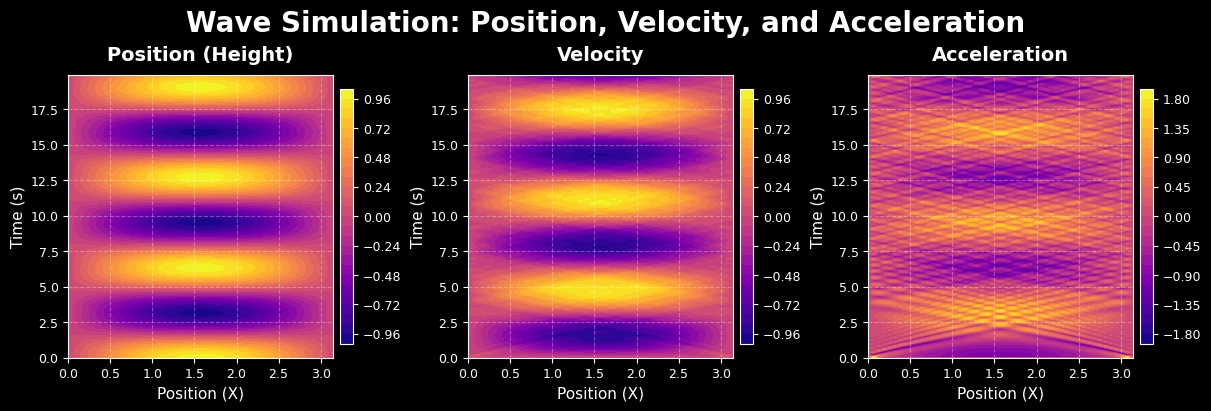

In [68]:

# Time array
time = np.arange(nt) * dt

# Night Mode Plots
plt.style.use("dark_background")

# Create one figure with three horizontal subplots
fig, axes = plt.subplots(1, 3,figsize=(12, 4),constrained_layout=True)

# Data, titles, and colormaps
plot_data = [
    (Z, "Position (Height)", "plasma"),
    (V, "Velocity", "plasma"),
    (A, "Acceleration", "plasma")
]

for ax, (data, title, cmap) in zip(axes, plot_data):

    cf = ax.contourf(X,time,data,levels=31,cmap=cmap)

    # Individual colorbar for each subplot
    cbar = fig.colorbar(cf, ax=ax, pad=0.03, shrink=0.9)
    cbar.ax.tick_params(labelsize=9)

    # Titles and axis labels
    ax.set_title(title, fontsize=14, fontweight="bold", pad=10)
    ax.set_xlabel("Position (X)", fontsize=11)
    ax.set_ylabel("Time (s)", fontsize=11)

    ax.tick_params(axis="both", labelsize=9)
    ax.grid(alpha=0.3, linestyle="--")

# Overall figure title
fig.suptitle("Wave Simulation: Position, Velocity, and Acceleration",fontsize=20,fontweight="bold")

# Save figure at high resolution
fig.savefig("Quick_Look_Plots.png",dpi=300,bbox_inches="tight")

plt.show()


_____________________

### GIF of Wave Model Simulation

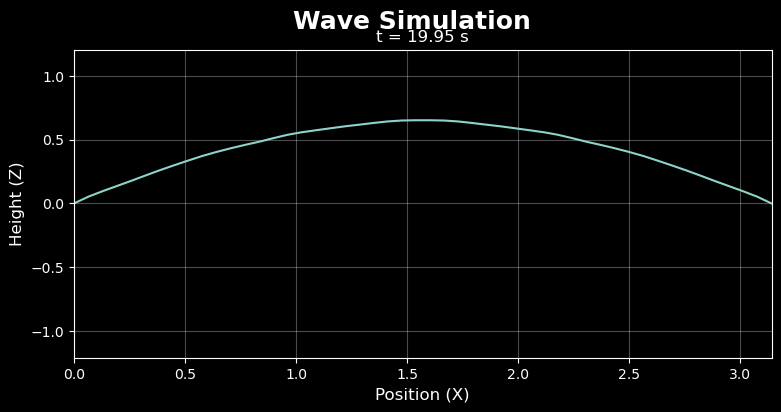

In [69]:
### Animate the frames

fig, ax = plt.subplots(figsize=(9, 4))
plt.style.use("dark_background")
plt.grid(alpha=0.3)
line, = ax.plot(X, Z[0], "-")            # 'o-' shows the individual columns

ax.set_xlim(x_min, x_max)
pad = 0.1 * (Z.max() - Z.min())
ax.set_ylim(Z.min() - pad, Z.max() + pad)  # fixed limits so the axes don't jump
ax.set_xlabel("Position (X)", fontsize=12)
ax.set_ylabel("Height (Z)", fontsize=12)
title = ax.set_title(f"t = 0.00 s")

fig.suptitle("Wave Simulation",fontsize=18,fontweight="bold")

def update(frame):
    line.set_ydata(Z[frame])
    title.set_text(f"t = {frame * dt:.2f} s")
    return line, title

ani = FuncAnimation(fig, update, frames=nt, interval=50, blit=False)
ani.save("Wave_Simulation.gif", writer="pillow", fps=30)

plt.show()